# Stellar limb darkening

The quadratic coefficients $(u_1, u_2)$ of the `batman` transit and the bolometric linear coefficient $u_{\rm bol}$ of the irradiance, fitted with ExoTiC-LD (Grant & Wakeford 2024) to the PHOENIX grid (MPS-ATLAS as a cross-check) at each host's $T_{\rm eff}$, log g and [Fe/H], and compared with the baselines `DEFAULT_U` and `DEFAULT_U_BOL`. ExoTiC-LD downloads one model file per host and grid into `inputs/stellar_model/ExoTiC-LD/` on first use.

In [1]:
import contextlib, io
import numpy as np
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from hyperphase.bands import instruments, JWST_BANDS
from hyperphase.defaults import DEFAULT_U, DEFAULT_U_BOL
from hyperphase.paper import PAPER_PLANETS
from hyperphase.targets import hi_planets_by_name
from hyperphase.stellar import bolometric_ld_profile, LD_GRID_TEFF_MIN, LD_MU_MIN, quad_ld
warnings.filterwarnings("ignore", message="pkg_resources is deprecated", category=UserWarning)   # raised by ExoTiC-LD's own import of pkg_resources; no effect on the fits

In [2]:
PLANETS = hi_planets_by_name(PAPER_PLANETS)      # the planets of the paper (the paper's table of targets)
REF = hi_planets_by_name("TOI-2431 b")           # planet of the profile figure
BANDS = instruments()                            # all bands of the repo; Spitzer/IRAC2 is shown but not used for the baseline

LD_MODELS = ("phoenix", "mps1")                  # main grid (PHOENIX, T_eff 2300-15000 K) and cross-check (MPS-ATLAS 1D, T_eff 3500-9000 K)
MU_MIN = LD_MU_MIN                               # mu below which quad_ld does not fit (shaded in the profile figure)
U_BOL = DEFAULT_U_BOL                                # adopted bolometric linear coefficient of the irradiance, for comparison

## 1. Quadratic coefficients of the transit

The transit is identical in both irradiance models and cancels in every comparison, so $(u_1, u_2)$ need to be plausible, not precise. Weighted with the forward model's band throughputs (`stellar.quad_ld`, $\mu \geq 0.1$); PHOENIX stops at 5.5 µm, so the MIRI bands drop out. `DEFAULT_U` is the median over the JWST bands and the paper's hosts, derived for an earlier sample; the second cell prints whether it still matches.

In [3]:
rows, profiles_ref = [], {}
with contextlib.redirect_stdout(io.StringIO()):   # quad_ld prints a note for every band beyond the grid's wavelength range; summarised below
    for ld_model in LD_MODELS:
        for planet in PLANETS.values():
            rows += quad_ld(planet, BANDS, ld_model)[0]
        profiles_ref[ld_model] = quad_ld(REF, BANDS, ld_model)[1]
ld = pd.DataFrame(rows)

# excluded from the baseline and the comparison: bands beyond the grid's wavelength range, hosts below its T_eff range
for m in LD_MODELS:
    out = ld[(ld.ld_model == m) & ~ld.covered].groupby("band").planet.nunique()
    cool = ld[(ld.ld_model == m) & ~ld.in_grid].planet.unique()
    if len(out): print(f"{m}: beyond the grid's wavelength range: " + ", ".join(f"{b} ({n} of {len(PLANETS)} hosts)" for b, n in out.items()))
    if len(cool): print(f"{m}: hosts below the grid's T_eff range: " + ", ".join(cool))

phoenix: beyond the grid's wavelength range: MIRI/F1280W (10 of 10 hosts), MIRI/F1500W (10 of 10 hosts), MIRI/F1800W (10 of 10 hosts), MIRI/LRS (10 of 10 hosts)


In [4]:
ok = ld[ld.in_grid & ld.covered]
main = ok[(ok.ld_model == LD_MODELS[0]) & ok.band.isin(JWST_BANDS)]
u_base = np.round(main[["u1", "u2"]].median().values, 2)
print(f"baseline (u1, u2) = ({u_base[0]:.2f}, {u_base[1]:.2f})   median of {len(main)} planet-band pairs, {LD_MODELS[0]} grid, JWST bands")
print(f"adopted DEFAULT_U (hyperphase/defaults.py) = {DEFAULT_U}" + ("" if np.allclose(u_base, DEFAULT_U) else "   (differs from this median; kept, since the transit cancels in every comparison)"))
print(f"range: u1 {main.u1.min():.3f} to {main.u1.max():.3f}, u2 {main.u2.min():.3f} to {main.u2.max():.3f}, u1 + u2 {(main.u1 + main.u2).min():.3f} to {(main.u1 + main.u2).max():.3f}")

both = ok.pivot_table(index=["planet", "band"], columns="ld_model", values=["u1", "u2"]).dropna()
d = both.xs(LD_MODELS[0], axis=1, level=1) - both.xs(LD_MODELS[1], axis=1, level=1)
print(f"{LD_MODELS[0]} - {LD_MODELS[1]} over {len(d)} common planet-band pairs: median |du1| = {d.u1.abs().median():.3f}, "
      f"median |du2| = {d.u2.abs().median():.3f}, max |d(u1 + u2)| = {(d.u1 + d.u2).abs().max():.3f}")

baseline (u1, u2) = (0.10, 0.14)   median of 20 planet-band pairs, phoenix grid, JWST bands
adopted DEFAULT_U (hyperphase/defaults.py) = (0.09, 0.14)   (differs from this median; kept, since the transit cancels in every comparison)
range: u1 0.082 to 0.120, u2 0.103 to 0.195, u1 + u2 0.185 to 0.303
phoenix - mps1 over 30 common planet-band pairs: median |du1| = 0.012, median |du2| = 0.017, max |d(u1 + u2)| = 0.010


## 2. Bolometric coefficient of the irradiance

One value per host and grid (`bolometric_ld_profile`: energy-weighted over the whole grid, least squares over $\mu \geq 0.1$), to compare with the adopted $u_{\rm bol}$. The fraction of $\sigma T_{\rm eff}^4$ outside each grid's range shows what PHOENIX misses beyond 5.5 µm.

In [5]:
bol = pd.DataFrame([dict(planet=pl.name, T_eff=pl.T2_eff, logg=pl.logg, ld_model=m, u_bol=u_bol, f_out=f_out)
                    for m in LD_MODELS for pl in PLANETS.values()
                    for _, _, u_bol, f_out in [bolometric_ld_profile(pl, m)]])
bol["in_grid"] = bol.T_eff >= bol.ld_model.map(LD_GRID_TEFF_MIN)

tab = bol.pivot(index="planet", columns="ld_model", values="u_bol")[list(LD_MODELS)]
tab = bol.groupby("planet")[["T_eff", "logg"]].first().join(tab).sort_values("T_eff")
print(f"bolometric linear coefficient per host (least squares over mu >= {MU_MIN}), adopted u_bol = {U_BOL}:")
print(tab.round({"T_eff": 0, "logg": 2, **{m: 3 for m in LD_MODELS}}).to_string())

good = bol[bol.in_grid]
print("\nmedian over hosts: " + ", ".join(f"{m} {good[good.ld_model == m].u_bol.median():.3f}" for m in LD_MODELS))
print("largest fraction of sigma T_eff^4 outside the grid's wavelength range: "
      + ", ".join(f"{m} {100 * bol[bol.ld_model == m].f_out.max():.1f} %" for m in LD_MODELS))
if (~bol.in_grid).any():
    print("below the T_eff range of the grid (nearest model):", bol.loc[~bol.in_grid, ["ld_model", "planet", "T_eff"]].to_string(index=False))

bolometric linear coefficient per host (least squares over mu >= 0.1), adopted u_bol = 0.5:
              T_eff  logg  phoenix   mps1
planet                                   
TOI-2431 b   4109.0  4.68    0.485  0.495
K2-141 b     4599.0  4.62    0.563  0.562
Kepler-78 b  5058.0  4.55    0.570  0.560
TOI-1798.02  5106.0  4.57    0.570  0.567
K2-131 b     5120.0  4.62    0.570  0.564
55 Cnc e     5172.0  4.43    0.573  0.572
TOI-561 b    5372.0  4.50    0.555  0.547
TOI-1444 b   5430.0  4.49    0.570  0.564
TOI-2260 b   5534.0  4.62    0.570  0.565
HD 80653 b   5959.0  4.34    0.568  0.549

median over hosts: phoenix 0.570, mps1 0.563
largest fraction of sigma T_eff^4 outside the grid's wavelength range: phoenix 1.0 %, mps1 0.0 %


## 3. Intensity profiles of TOI-2431 b

Model intensities (points) and quadratic fits (lines) per band, with the baseline, the bolometric profile (grey squares) and the linear law of $u_{\rm bol}$; $\mu < 0.1$ (shaded) is not fitted.

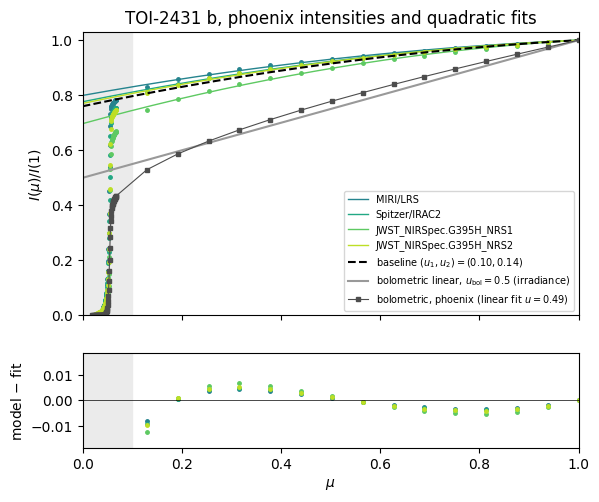

bolometric phoenix profile of TOI-2431 b: least-squares linear u = 0.485 (mu >= 0.1); 1.0 % of sigma T_eff^4 lies outside the grid's wavelength range


In [6]:
quad = lambda mu, u: 1 - u[0] * (1 - mu) - u[1] * (1 - mu) ** 2
mu = np.linspace(0, 1, 300)
ref = ld[(ld.ld_model == LD_MODELS[0]) & (ld.planet == REF.name)].set_index("band")
colors = dict(zip(BANDS, plt.cm.viridis(np.linspace(0, 0.9, len(BANDS)))))

fig, (ax, axr) = plt.subplots(2, 1, figsize=(6.4, 5.4), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
r_max = 0.
for band, (m, I) in profiles_ref[LD_MODELS[0]].items():
    u = ref.loc[band, ["u1", "u2"]].values.astype(float)
    ax.plot(m, I, "o", ms=2.5, color=colors[band])
    ax.plot(mu, quad(mu, u), lw=1, color=colors[band], label=band)
    axr.plot(m, I - quad(m, u), "o", ms=2.5, color=colors[band])
    r_max = max(r_max, np.abs(I - quad(m, u))[m >= MU_MIN].max())
ax.plot(mu, quad(mu, u_base), "k--", lw=1.5, label=rf"baseline $(u_1, u_2) = ({u_base[0]:.2f}, {u_base[1]:.2f})$")
ax.plot(mu, 1 - U_BOL * (1 - mu), color="0.6", lw=1.5, label=rf"bolometric linear, $u_{{\rm bol}} = {U_BOL}$ (irradiance)")
mu_bol, I_bol, u_bol, f_out = bolometric_ld_profile(REF, LD_MODELS[0])   # energy-weighted over the whole grid
ax.plot(mu_bol, I_bol, "s-", ms=2.5, lw=0.8, color="0.3", label=rf"bolometric, {LD_MODELS[0]} (linear fit $u = {u_bol:.2f}$)")
for a in (ax, axr):
    a.axvspan(0, MU_MIN, color="0.92", zorder=0)
axr.axhline(0, color="k", lw=0.5)
ax.set(ylabel=r"$I(\mu)/I(1)$", ylim=(0, 1.03), title=f"{REF.name}, {LD_MODELS[0]} intensities and quadratic fits")
axr.set(xlabel=r"$\mu$", ylabel="model $-$ fit", xlim=(0, 1), ylim=(-1.5 * r_max, 1.5 * r_max))
ax.legend(fontsize=7, loc="lower right")
plt.show()
print(f"bolometric {LD_MODELS[0]} profile of {REF.name}: least-squares linear u = {u_bol:.3f} (mu >= {MU_MIN}); "
      f"{100 * f_out:.1f} % of sigma T_eff^4 lies outside the grid's wavelength range")

## 4. Coefficients across the planets of the paper

One point per host and band (PHOENIX), coloured by $T_{\rm eff}$; the star marks the baseline, a red edge a host below the grid's $T_{\rm eff}$ range.

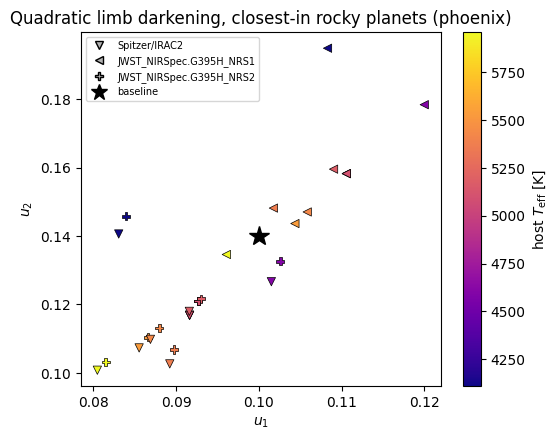

In [7]:
markers = dict(zip(BANDS, "osD^v<P>"))
d = ld[(ld.ld_model == LD_MODELS[0]) & ld.covered]
fig, ax = plt.subplots(figsize=(5.8, 4.6))
for band, g in d.groupby("band"):
    sc = ax.scatter(g.u1, g.u2, c=g.T_eff, cmap="plasma", vmin=d.T_eff.min(), vmax=d.T_eff.max(), marker=markers[band],
                    s=36, edgecolors=np.where(g.in_grid, "k", "r"), linewidths=0.5)
ax.plot(*u_base, "k*", ms=15)
handles = [plt.Line2D([], [], marker=markers[b], ls="", color="0.7", mec="k", label=b) for b in BANDS if b in set(d.band)]
handles += [plt.Line2D([], [], marker="*", ls="", color="k", ms=12, label="baseline")]
ax.legend(handles=handles, fontsize=7)
fig.colorbar(sc, ax=ax, label=r"host $T_{\rm eff}$ [K]")
ax.set(xlabel="$u_1$", ylabel="$u_2$", title=f"Quadratic limb darkening, closest-in rocky planets ({LD_MODELS[0]})")
plt.show()